# 01 · Data quality

Checks that the daily dataset built in Phase 1 is complete and trustworthy before any model sees it. Rebuild the data with `uv run python scripts/download_data.py` and `uv run python scripts/build_dataset.py`, then run this notebook top to bottom.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fxml.config import load_config
from fxml import viz

cfg = load_config()
viz.apply_style()
colors = viz.pair_colors(cfg.pairs)
panel = pd.read_parquet(cfg.paths.processed / "daily_bars.parquet")
macro = pd.read_parquet(cfg.paths.processed / "macro.parquet")
rates = pd.read_parquet(cfg.paths.processed / "policy_rates.parquet")
pairs = list(cfg.pairs)
pd.set_option("display.precision", 4)

## Coverage

Share of expected trading days (weekdays except 25 December and 1 January) present for each symbol, and how many sessions were thin (under half a day of 1-minute bars).

In [2]:
from fxml.data.quality import coverage_report
coverage_report(panel)

,first,last,days,expected,coverage_pct,missing,thin_days,median_minutes
AUDUSD,2006-01-03,2026-10-23,5408,5399,100.0000,0,30,1428.0
EURUSD,2006-01-03,2026-10-23,5407,5399,100.0000,0,21,1433.0
GBPUSD,2006-01-03,2026-10-23,5407,5399,100.0000,0,22,1433.0
NZDUSD,2006-01-03,2026-10-23,5407,5399,100.0000,0,41,1426.0
SPXUSD,2010-11-15,2026-10-23,4118,4138,99.4683,22,143,1215.0
USDCAD,2006-01-03,2026-10-23,5407,5399,100.0000,0,38,1421.0
USDCHF,2006-01-03,2026-10-23,5406,5399,99.9815,1,22,1426.0
USDJPY,2006-01-03,2026-10-23,5407,5399,100.0000,0,20,1431.0
XAUUSD,2009-03-16,2026-10-23,4553,4571,99.6062,18,15,1379.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


PosixPath('/Users/adisid07/Desktop/3-2 BITS Goa/ML/Project/fx-regime-forecasting/reports/figures/data_session_coverage.png')

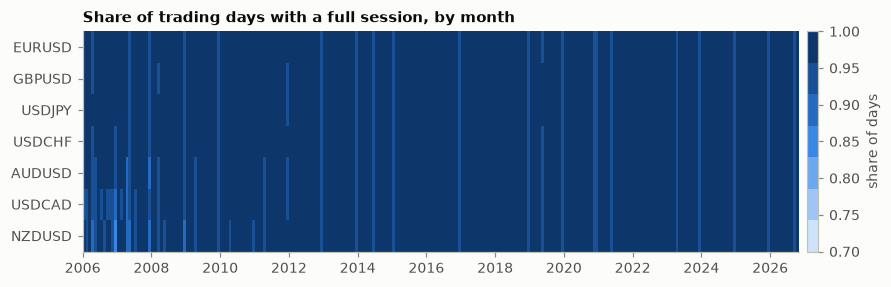

In [3]:
# Share of each month's trading days with a full session, per pair
full = (~panel["thin"]).rename("full").reset_index()
full = full[full["symbol"].isin(pairs)]
monthly = full.groupby(["symbol", pd.Grouper(key="date", freq="MS")])["full"].mean().unstack(0)[pairs]

month_edges = monthly.index.append(pd.DatetimeIndex([monthly.index[-1] + pd.offsets.MonthBegin()]))
fig, ax = plt.subplots(figsize=(10, 2.6))
mesh = ax.pcolormesh(month_edges, np.arange(len(pairs) + 1), monthly.T.values,
                     cmap=plt.matplotlib.colors.ListedColormap(viz.SEQUENTIAL_BLUE),
                     vmin=0.7, vmax=1.0, shading="flat")
ax.set_yticks(np.arange(len(pairs)) + 0.5, pairs)
ax.invert_yaxis()
ax.grid(False)
ax.set_title("Share of trading days with a full session, by month")
fig.colorbar(mesh, ax=ax, pad=0.01, label="share of days")
viz.save(fig, "data_session_coverage")

## Agreement with an independent source

The Federal Reserve's H.10 release publishes noon New York rates. We take our own price at 12:00 New York from the 5-minute bars, so daily returns of the two should be almost identical.

In [4]:
from fxml.data.quality import h10_check
h10_check(panel, macro, cfg.pairs)

,days,return_corr,return_corr_winter,return_corr_summer,mean_abs_level_gap_pct
EURUSD,5210,0.9965,0.9984,0.9953,0.0120
GBPUSD,5210,0.9944,0.9989,0.9920,0.0179
USDJPY,5210,0.9959,0.9978,0.9949,0.0128
USDCHF,5209,0.9969,0.9996,0.9951,0.0146
AUDUSD,5210,0.9968,0.9984,0.9961,0.0240
USDCAD,5210,0.9957,0.9972,0.9948,0.0164
NZDUSD,5210,0.9969,0.9982,0.9963,0.0328


/var/folders/gn/94ntv0hn0jl7z5wry9g27xq40000gn/T/ipykernel_15247/961866686.py:3: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  both = pd.concat({"ours": panel.xs(pair, level="symbol")["noon"],
/var/folders/gn/94ntv0hn0jl7z5wry9g27xq40000gn/T/ipykernel_15247/961866686.py:3: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  both = pd.concat({"ours": panel.xs(pair, level="symbol")["noon"],
/var/folders/gn/94ntv0hn0jl7z5wry9g27xq40000gn/T/ipykernel_15247/961866686.py:3: Pandas4Warning: Sorting by de

PosixPath('/Users/adisid07/Desktop/3-2 BITS Goa/ML/Project/fx-regime-forecasting/reports/figures/data_h10_agreement.png')

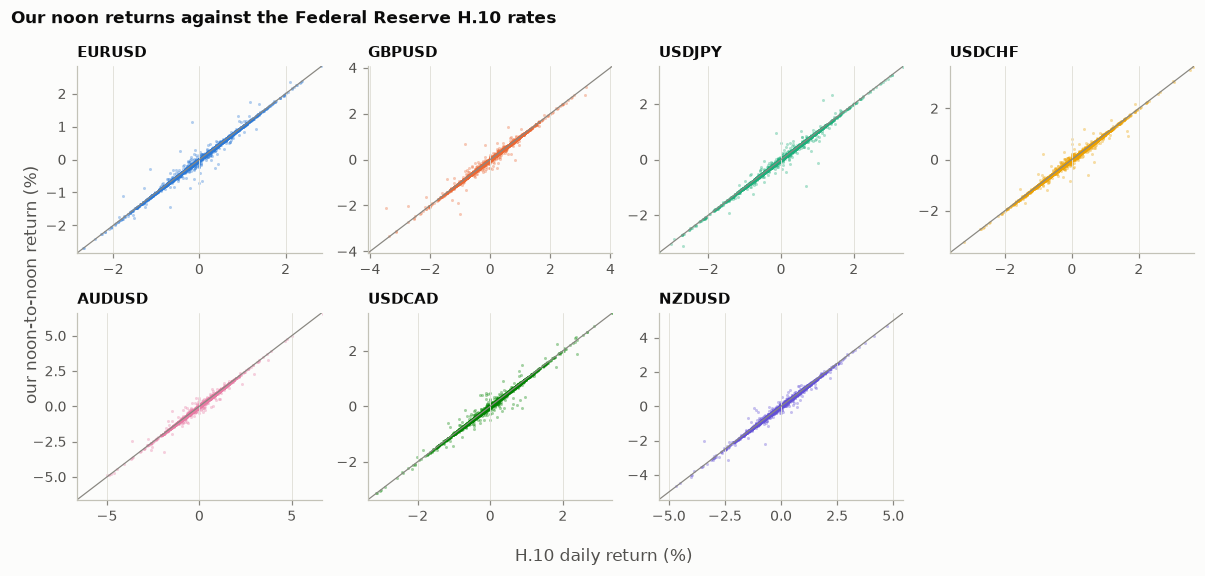

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5.2), sharex=False)
for ax, pair in zip(axes.flat, pairs):
    both = pd.concat({"ours": panel.xs(pair, level="symbol")["noon"],
                      "fed": macro[f"h10_{pair}"]}, axis=1).dropna()
    r = 100 * np.log(both).diff().dropna()
    ax.scatter(r["fed"], r["ours"], s=4, color=colors[pair], alpha=0.35, linewidths=0)
    lim = np.nanpercentile(np.abs(r.values), 99.9)
    ax.plot([-lim, lim], [-lim, lim], color=viz.INK_MUTED, lw=0.8)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), title=pair)
    ax.grid(axis="both")
axes.flat[-1].axis("off")
fig.supxlabel("H.10 daily return (%)", color=viz.INK_SECONDARY)
fig.supylabel("our noon-to-noon return (%)", color=viz.INK_SECONDARY)
fig.suptitle("Our noon returns against the Federal Reserve H.10 rates", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
viz.save(fig, "data_h10_agreement")

## Largest daily moves

The biggest close-to-close moves should line up with real events (for example USD/CHF on 15 January 2015). Anything that does not is a data error to investigate.

In [6]:
from fxml.data.quality import largest_moves
largest_moves(panel)

,date,symbol,ret,abs_ret_pct
0,2008-10-13,AUDUSD,0.0826,8.2586
1,2008-10-24,AUDUSD,-0.0737,7.3718
2,2008-10-06,AUDUSD,-0.0691,6.9113
3,2008-10-28,AUDUSD,0.0642,6.4216
4,2008-10-10,AUDUSD,-0.0615,6.1474
5,2009-03-18,EURUSD,0.0345,3.4503
6,2015-12-03,EURUSD,0.0302,3.0155
7,2008-12-17,EURUSD,0.0288,2.8843
8,2008-11-24,EURUSD,0.0285,2.8497
9,2008-11-04,EURUSD,0.0264,2.6379


## Policy rates and market context

PosixPath('/Users/adisid07/Desktop/3-2 BITS Goa/ML/Project/fx-regime-forecasting/reports/figures/data_policy_rates.png')

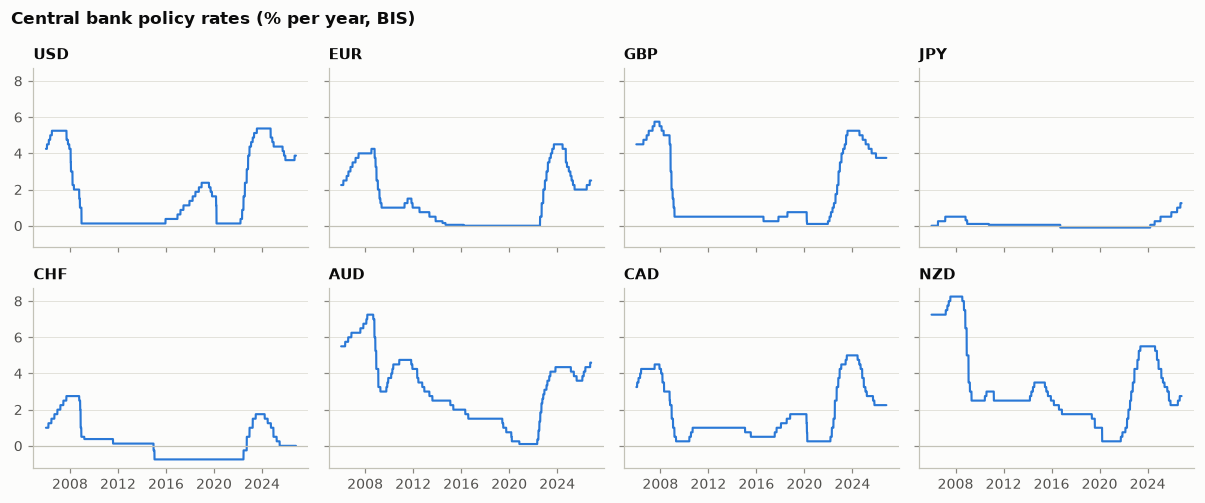

In [7]:
currencies = list(rates.columns)
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, ccy in zip(axes.flat, currencies):
    ax.plot(rates.index, rates[ccy], color=viz.CATEGORICAL[0])
    ax.axhline(0, color=viz.BASELINE, lw=0.8)
    ax.set_title(ccy)
fig.suptitle("Central bank policy rates (% per year, BIS)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
viz.save(fig, "data_policy_rates")

PosixPath('/Users/adisid07/Desktop/3-2 BITS Goa/ML/Project/fx-regime-forecasting/reports/figures/data_market_context.png')

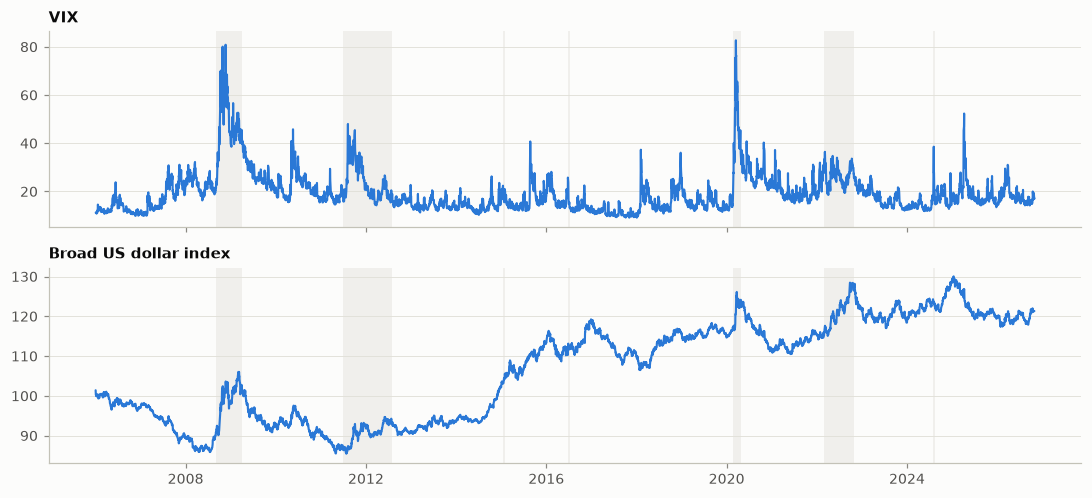

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
for ax, (col, title) in zip(axes, [("vix", "VIX"), ("broad_dollar", "Broad US dollar index")]):
    viz.shade_stress(ax)
    ax.plot(macro.index, macro[col].ffill(), color=viz.CATEGORICAL[0])
    ax.set_title(title)
fig.tight_layout()
viz.save(fig, "data_market_context")

## Findings

- **Coverage.** The seven pairs cover 100% of expected trading days from January 2006 to October 2026; USD/CHF misses a single day. Gold (99.6%) and the S&P 500 (99.5%) miss some US exchange holidays. Each pair has 20–41 thin sessions in 21 years, mostly around Christmas and New Year, flagged in the `thin` column.
- **Timestamps.** HistData's FAQ says its clock is fixed EST, but the data follows New York daylight saving time. Read correctly, our noon returns match the Federal Reserve's H.10 noon rates with a correlation of 0.994–0.997, at least 0.992 in both winter and summer, and an average price gap of 1–3 pips. This also confirms the 17:00 New York day boundary.
- **Bad ticks.** One impossible wick was removed: NZD/USD on 23 December 2008 shows a high of 2.17 against a price of 0.57. Every other extreme is under 3% and lines up with a real event.
- **Largest moves** match documented episodes:
  - USD/CHF −19.5% on 15 January 2015 and +9% on 6 September 2011, when the franc cap was removed and introduced;
  - GBP/USD −8.8% after the Brexit vote;
  - the October 2008 collapse of the Australian and New Zealand dollars;
  - March 2020.
- **Policy rates** are complete for all eight currencies. The yen rate is carried back at 0% for January–March 2006, before the BIS daily series begins.
